# Q1: ผู้ใช้บริการวันธรรมดา vs วันหยุดสุดสัปดาห์
**กลุ่ม:** Loading Brain... 1%

**คำถาม:** (1) เปรียบเทียบจำนวนผู้ใช้บริการเฉลี่ยต่อวันในวันธรรมดาและวันหยุดสุดสัปดาห์ (2) ตรวจสอบว่ารูปแบบดังกล่าวเปลี่ยนไปในแต่ละเดือนหรือไม่

**ขอบเขต**
- ปี 2568 (2025) เท่านั้น เพราะครบ 12 เดือน
- หน่วยคนเท่านั้น ไม่รวมคันตามที่โจทย์กำหนด และตัด 3 บริการที่ข้อมูลไม่ครบทั้งปี (รถร่วม (หมวด 1), รถหมวด 3, รถหมวด 4) เหลือ 36 บริการ
- จัดกลุ่มตามวัตถุประสงค์ ยอดของกลุ่ม = ผลรวมของค่าเฉลี่ยต่อวันของแต่ละบริการ (หน่วยเป็น คน-เที่ยว ผู้โดยสารคนเดียวที่เดินทางขาไปและขากลับนับ 2 ครั้ง)

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["font.family"] = "Tahoma"     # แสดงภาษาไทยในกราฟ

# โหลดข้อมูลที่เตรียมแล้วจาก 01 และแปลงวันที่กลับเป็น datetime
df = pd.read_csv("../outputs/prepared_daily.csv")
df["date"] = pd.to_datetime(df["date"], format= "%Y-%m-%d")
print("ขนาด: ", df.shape)

from pathlib import Path

# โฟลเดอร์เก็บรูป (สร้างให้ถ้ายังไม่มี)
FIG_DIR = Path("../outputs/figures")
FIG_DIR.mkdir(parents= True, exist_ok= True)

ขนาด:  (18705, 18)


In [10]:
# ปี 2025, หน่วยคน และตัด 3 บริการที่ข้อมูลไม่ครบทั้งปี
exclude = ["รถร่วม (หมวด 1)", "รถหมวด 3", "รถหมวด 4"]
df_q1 = df[(df["year"] == 2025) & (df["หน่วย"] == "คน") & ~df["ยานพาหนะ/ท่า"].isin(exclude)].copy()

# ป้ายประเภทวันภาษาไทย ไว้ใช้ในกราฟ
df_q1["day_type"] = df_q1["is_weekend"].map({0: "วันธรรมดา", 1: "วันหยุดสุดสัปดาห์"})

print("ขนาด: ", df_q1.shape, "| บริการ: ", df_q1["ยานพาหนะ/ท่า"].nunique())
display(df_q1.groupby("วัตถุประสงค์")["ยานพาหนะ/ท่า"].nunique())

# ลำดับกลุ่มในกราฟ
order = ["การเดินทางภายในจังหวัด/กรุงเทพ", "การเดินทางระหว่างจังหวัด", "การเดินทางระหว่างประเทศ"]

ขนาด:  (13140, 19) | บริการ:  36


วัตถุประสงค์
การเดินทางภายในจังหวัด/กรุงเทพ    14
การเดินทางระหว่างจังหวัด           8
การเดินทางระหว่างประเทศ           14
Name: ยานพาหนะ/ท่า, dtype: int64

## 1.1 เปรียบเทียบผู้ใช้บริการเฉลี่ยต่อวัน (รูปที่ 1)

1. หาค่าเฉลี่ยต่อวันของแต่ละบริการ แยกวันธรรมดา / วันหยุด
2. บวกค่าเฉลี่ยของบริการในกลุ่มเดียวกัน = ยอดเฉลี่ยต่อวันของกลุ่ม
3. pct_diff = (วันหยุด − วันธรรมดา) ÷ วันธรรมดา × 100

ตัวอย่างคิดมือ (ในเมือง): (1,967,730 − 2,678,544) ÷ 2,678,544 × 100 = −26.5%

In [11]:
# 1) ค่าเฉลี่ยต่อวันของแต่ละบริการ แยกประเภทวัน
svc = df_q1.groupby(["วัตถุประสงค์", "ยานพาหนะ/ท่า", "day_type"], as_index= False).agg(
    avg_daily= ("qty", "mean"))

# 2) รวมเป็นยอดของกลุ่ม (บวกค่าเฉลี่ยของแต่ละบริการ)
purpose = svc.groupby(["วัตถุประสงค์", "day_type"], as_index= False).agg(
    avg_daily= ("avg_daily", "sum"))

# 3) % ต่าง: avg_daily_x = วันธรรมดา, avg_daily_y = วันหยุด
wd = purpose[purpose["day_type"] == "วันธรรมดา"][["วัตถุประสงค์", "avg_daily"]]
we = purpose[purpose["day_type"] == "วันหยุดสุดสัปดาห์"][["วัตถุประสงค์", "avg_daily"]]
diff = pd.merge(wd, we, on= "วัตถุประสงค์", how= "inner", validate= "one_to_one")
diff["pct_diff"] = (diff["avg_daily_y"] - diff["avg_daily_x"]) / diff["avg_daily_x"] * 100
display(diff.round(1))

,วัตถุประสงค์,avg_daily_x,avg_daily_y,pct_diff
0,การเดินทางภายในจังหวัด/กรุงเทพ,2678544.3,1967730.3,-26.5
1,การเดินทางระหว่างจังหวัด,252937.7,263219.3,4.1
2,การเดินทางระหว่างประเทศ,203985.2,215085.0,5.4


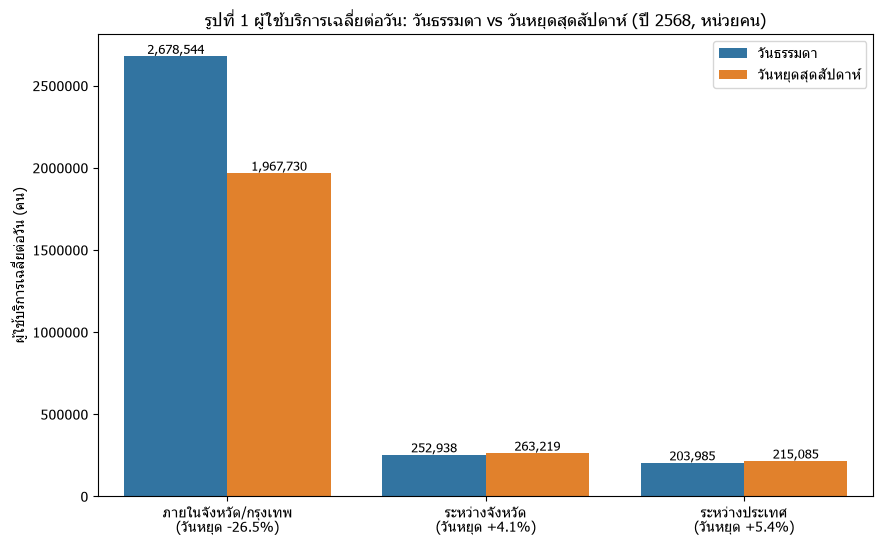

In [12]:
# ชื่อแกน x พร้อม % ต่าง
labels = []
for p in order:
    v = diff.loc[diff["วัตถุประสงค์"] == p, "pct_diff"].iloc[0]
    labels.append(p.replace("การเดินทาง", "") + f"\n(วันหยุด {v:+.1f}%)")

plt.figure(figsize= (10, 6))
ax = sns.barplot(data= purpose, x= "วัตถุประสงค์", y= "avg_daily", hue= "day_type", order= order)
for c in ax.containers:
    ax.bar_label(c, fmt= "{:,.0f}", fontsize= 9)        # ตัวเลขบนแท่ง
ax.set_xticks(range(3))
ax.set_xticklabels(labels)
plt.ticklabel_format(style= "plain", axis= "y")          # ไม่ให้แกนแสดงเป็น 1e6
plt.title("รูปที่ 1 ผู้ใช้บริการเฉลี่ยต่อวัน: วันธรรมดา vs วันหยุดสุดสัปดาห์ (ปี 2568, หน่วยคน)")
plt.xlabel("")
plt.ylabel("ผู้ใช้บริการเฉลี่ยต่อวัน (คน)")
plt.legend(title= "")
plt.savefig(FIG_DIR / "q1_fig1_weekday_weekend.png", dpi= 150, bbox_inches= "tight")   # บันทึกรูป
plt.show()

**วิธีอ่าน:** แท่งน้ำเงิน = เฉลี่ยต่อวันในวันธรรมดา, แท่งส้ม = วันหยุดสุดสัปดาห์ และวงเล็บใต้ชื่อกลุ่มคือ วันหยุดต่างจากวันธรรมดากี่ %

**ผล:**
- **ในเมือง:** วันธรรมดาเฉลี่ย 2,678,544 คน/วัน วันหยุดเหลือ 1,967,730 คน/วัน **ลดลง 26.5%** (ประมาณ 710,000 คน/วัน)
- **ระหว่างจังหวัด:** 252,938 → 263,219 คน/วัน **วันหยุดมากกว่า 4.1%**
- **ระหว่างประเทศ:** 203,985 → 215,085 คน/วัน **วันหยุดมากกว่า 5.4%**
- สรุป: การเดินทางในเมืองพึ่งวันธรรมดาชัดเจน ส่วนการเดินทางระยะไกลวันหยุดสูงกว่าเล็กน้อย

## 1.2 รูปแบบตามวันในสัปดาห์ (รูปที่ 2)

ใช้ ratio_to_median (1 = วันปกติของบริการ) เพื่อเทียบบริการที่ขนาดต่างกันในตารางเดียว เรียงแถวตามค่าเฉลี่ยเสาร์–อาทิตย์ (AIE314 บทที่ 7 หน้า 23–26)
*pivot_table ไม่พบในเอกสารวิชา ใช้จัดตาราง บริการ × วันในสัปดาห์ สำหรับ heatmap*

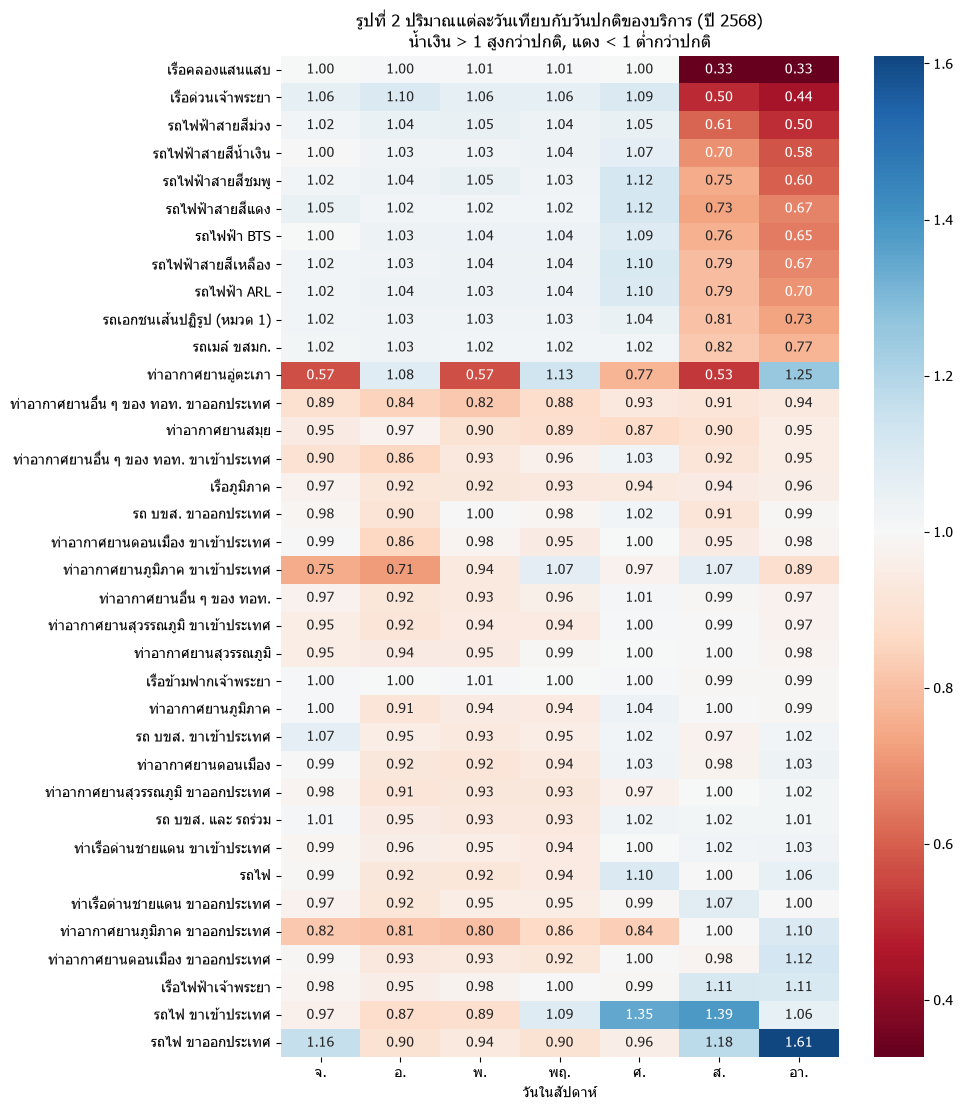

,ศ.,อา.
ยานพาหนะ/ท่า,,
รถไฟฟ้าสายสีม่วง,1.05,0.50
รถไฟฟ้าสายสีน้ำเงิน,1.07,0.58
รถไฟฟ้าสายสีชมพู,1.12,0.60
รถไฟฟ้าสายสีแดง,1.12,0.67
รถไฟฟ้า BTS,1.09,0.65
รถไฟฟ้าสายสีเหลือง,1.10,0.67
รถไฟฟ้า ARL,1.10,0.70


In [13]:
# ตาราง บริการ × วันในสัปดาห์ ค่า = มัธยฐาน ratio_to_median (1 = วันปกติของบริการ)
heat = df_q1.pivot_table(index= "ยานพาหนะ/ท่า", columns= "day_of_week",
                         values= "ratio_to_median", aggfunc= "median")
heat.columns = ["จ.", "อ.", "พ.", "พฤ.", "ศ.", "ส.", "อา."]

# เรียงแถวตามค่าเฉลี่ยเสาร์-อาทิตย์ (บริการที่วันหยุดลดมากอยู่บนสุด)
heat["weekend_avg"] = (heat["ส."] + heat["อา."]) / 2
heat = heat.sort_values("weekend_avg")
heat = heat[["จ.", "อ.", "พ.", "พฤ.", "ศ.", "ส.", "อา."]]

plt.figure(figsize= (9, 13))
sns.heatmap(heat, cmap= "RdBu", center= 1, annot= True, fmt= ".2f")
plt.title("รูปที่ 2 ปริมาณแต่ละวันเทียบกับวันปกติของบริการ (ปี 2568)\nน้ำเงิน > 1 สูงกว่าปกติ, แดง < 1 ต่ำกว่าปกติ")
plt.xlabel("วันในสัปดาห์")
plt.ylabel("")
plt.savefig(FIG_DIR / "q1_fig2_day_of_week_heatmap.png", dpi= 150, bbox_inches= "tight")   # บันทึกรูป
plt.show()

# ตัวเลขสำคัญ: รถไฟฟ้าวันศุกร์ vs วันอาทิตย์
rail = heat.index.str.contains("รถไฟฟ้า", regex= False)
display(heat.loc[rail, ["ศ.", "อา."]].round(2))

**วิธีอ่าน:** แต่ละช่อง = ปริมาณวันนั้นเทียบกับวันปกติของบริการ (1.00 = ปกติ) แดง = ต่ำกว่าปกติ, น้ำเงิน = สูงกว่าปกติ

**ผล:**
- แถวบน (เรือ รถไฟฟ้า รถเมล์): จ.–ศ. ประมาณ 1.00–1.12 แล้วลดลงเสาร์–อาทิตย์ เช่น เรือคลองแสนแสบ ส./อา. เหลือ **0.33 / 0.33**
- รถไฟฟ้า 7 สาย: วันศุกร์ **1.05–1.12** (สูงสุดหรือเท่ากับวันสูงสุดของสัปดาห์) ส่วนวันอาทิตย์ **0.50–0.70** (ต่ำสุด)
- แถวล่าง (รถไฟระหว่างประเทศ เรือไฟฟ้าเจ้าพระยา): วันหยุดสูงกว่าปกติ เช่น รถไฟ ขาออกประเทศ วันอาทิตย์ **1.61**
- ท่าอากาศยานอู่ตะเภา แต่ละวันขึ้นลงมาก (0.53–1.25) เพราะเที่ยวบินไม่ได้มีทุกวัน ไม่ใช่รูปแบบวันหยุด

## 1.3 รูปแบบเปลี่ยนไปในแต่ละเดือนหรือไม่ (รูปที่ 3)

ใช้วิธีเดียวกับรูปที่ 1 แต่แยกรายเดือน: pct_diff ของแต่ละกลุ่มในแต่ละเดือน ถ้าเครื่องหมาย (บวก/ลบ) เหมือนเดิมทุกเดือน แปลว่ารูปแบบไม่เปลี่ยนทิศทาง

In [14]:
# วิธีเดียวกับรูปที่ 1 แต่แยกรายเดือน
svc_m = df_q1.groupby(["วัตถุประสงค์", "ยานพาหนะ/ท่า", "month", "day_type"], as_index= False).agg(
    avg_daily= ("qty", "mean"))
pm = svc_m.groupby(["วัตถุประสงค์", "month", "day_type"], as_index= False).agg(
    avg_daily= ("avg_daily", "sum"))

wdm = pm[pm["day_type"] == "วันธรรมดา"][["วัตถุประสงค์", "month", "avg_daily"]]
wem = pm[pm["day_type"] == "วันหยุดสุดสัปดาห์"][["วัตถุประสงค์", "month", "avg_daily"]]
mdiff = pd.merge(wdm, wem, on= ["วัตถุประสงค์", "month"], how= "inner", validate= "one_to_one")
mdiff["pct_diff"] = (mdiff["avg_daily_y"] - mdiff["avg_daily_x"]) / mdiff["avg_daily_x"] * 100

# เดือนที่ต่างน้อยสุด / มากสุด ของแต่ละกลุ่ม
for p in order:
    g = mdiff[mdiff["วัตถุประสงค์"] == p].sort_values("pct_diff")
    print(p, "| น้อยสุด: เดือน", g["month"].iloc[0], "=", round(g["pct_diff"].iloc[0], 1),
          "% | มากสุด: เดือน", g["month"].iloc[-1], "=", round(g["pct_diff"].iloc[-1], 1), "%")

การเดินทางภายในจังหวัด/กรุงเทพ | น้อยสุด: เดือน 9 = -32.0 % | มากสุด: เดือน 4 = -21.9 %
การเดินทางระหว่างจังหวัด | น้อยสุด: เดือน 1 = 1.9 % | มากสุด: เดือน 2 = 7.3 %
การเดินทางระหว่างประเทศ | น้อยสุด: เดือน 10 = 4.0 % | มากสุด: เดือน 3 = 8.0 %


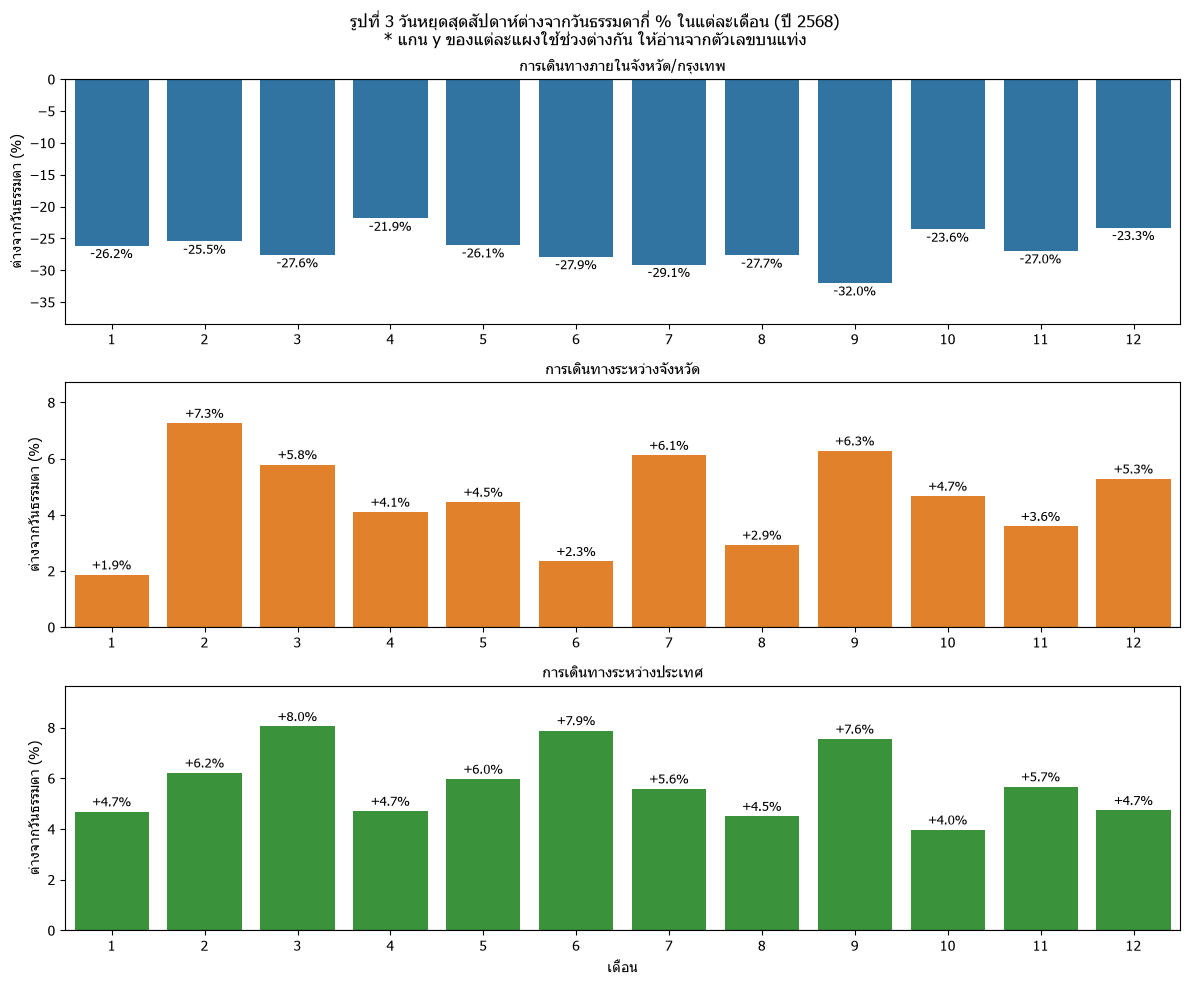

In [15]:
plt.figure(figsize= (12, 10))
for k, p in enumerate(order):
    plt.subplot(3, 1, k + 1)
    g = mdiff[mdiff["วัตถุประสงค์"] == p]
    ax = sns.barplot(data= g, x= "month", y= "pct_diff", color= "C" + str(k))
    ax.bar_label(ax.containers[0], fmt= "{:+.1f}%", fontsize= 9, padding= 2)   # ตัวเลขบนแท่ง
    plt.axhline(0, color= "black", linewidth= 0.8)                 # เส้น 0% = เท่ากับวันธรรมดา
    plt.title(p, fontsize= 11)
    plt.xlabel("")
    plt.ylabel("ต่างจากวันธรรมดา (%)")
    plt.margins(y= 0.2)                                            # เผื่อที่ให้ตัวเลขบนแท่ง
plt.xlabel("เดือน")
plt.suptitle("รูปที่ 3 วันหยุดสุดสัปดาห์ต่างจากวันธรรมดากี่ % ในแต่ละเดือน (ปี 2568)\n"
             "* แกน y ของแต่ละแผงใช้ช่วงต่างกัน ให้อ่านจากตัวเลขบนแท่ง")
plt.tight_layout()
plt.savefig(FIG_DIR / "q1_fig3_monthly_pct_diff.png", dpi= 150, bbox_inches= "tight")   # บันทึกรูป
plt.show()

**วิธีอ่าน:** แท่งลง (ลบ) = วันหยุดคนน้อยกว่าวันธรรมดา, แท่งขึ้น (บวก) = วันหยุดคนมากกว่า

**ผล: รูปแบบไม่เปลี่ยนทิศทางเลยตลอด 12 เดือน เปลี่ยนแค่ขนาด**
- **ในเมือง:** วันหยุดต่ำกว่าวันธรรมดา **ทุกเดือน** ระหว่าง −21.9% (เม.ย.) ถึง −32.0% (ก.ย.)
- **ระหว่างจังหวัด:** วันหยุดสูงกว่า **ทุกเดือน** ระหว่าง +1.9% (ม.ค.) ถึง +7.3% (ก.พ.)
- **ระหว่างประเทศ:** วันหยุดสูงกว่า **ทุกเดือน** ระหว่าง +4.0% (ต.ค.) ถึง +8.0% (มี.ค.)

## สรุปคำตอบ Q1

1. **เปรียบเทียบเฉลี่ยต่อวัน (รูปที่ 1):** การเดินทางในเมือง วันหยุดลดลง 26.5% (2,678,544 → 1,967,730 คน/วัน) ส่วนระหว่างจังหวัด (+4.1%) และระหว่างประเทศ (+5.4%) วันหยุดสูงกว่าวันธรรมดาเล็กน้อย
2. **ตามวันในสัปดาห์ (รูปที่ 2):** รถไฟฟ้าสูงสุดวันศุกร์ (1.05–1.12 เท่าของวันปกติ) และต่ำสุดวันอาทิตย์ (0.50–0.70)
3. **เปลี่ยนไปในแต่ละเดือนหรือไม่ (รูปที่ 3):** ทิศทางไม่เปลี่ยนทั้ง 12 เดือน ในเมืองติดลบทุกเดือน (−21.9% ถึง −32.0%) ระหว่างจังหวัดและระหว่างประเทศเป็นบวกทุกเดือน ขนาดของความต่างเปลี่ยนแค่ไม่กี่ %

**ข้อจำกัด:** ข้อมูลไม่มีวันหยุดนักขัตฤกษ์ วันหยุดที่ตรงกับ จ.–ศ. จึงนับเป็นวันธรรมดา / ตัวเลขเป็น คน-เที่ยว ไม่ใช่จำนวนคนไม่ซ้ำ / ไม่รวมบริการหน่วยคัน (ทางด่วน, 10 จุดสำรวจ) และรถหมวด 3/4 ที่ข้อมูลไม่ครบ

## บันทึกผลลัพธ์ Q1
ตารางรายบริการ (36 บริการ): ค่าเฉลี่ยต่อวันวันธรรมดา/วันหยุด และ % ต่าง ใช้สร้างรูปที่ 1 (บวกตามวัตถุประสงค์ = ยอดของกลุ่ม)

In [16]:
# ตารางผลรายบริการ: วันธรรมดา vs วันหยุด (ใช้สร้างรูปที่ 1)
s_wd = svc[svc["day_type"] == "วันธรรมดา"][["วัตถุประสงค์", "ยานพาหนะ/ท่า", "avg_daily"]]
s_we = svc[svc["day_type"] == "วันหยุดสุดสัปดาห์"][["วัตถุประสงค์", "ยานพาหนะ/ท่า", "avg_daily"]]
q1_out = pd.merge(s_wd, s_we, on= ["วัตถุประสงค์", "ยานพาหนะ/ท่า"], how= "inner", validate= "one_to_one")
q1_out = q1_out.rename(columns= {"avg_daily_x": "avg_weekday", "avg_daily_y": "avg_weekend"})
q1_out["pct_diff"] = (q1_out["avg_weekend"] - q1_out["avg_weekday"]) / q1_out["avg_weekday"] * 100

q1_out.to_csv("../outputs/q1_weekday_weekend.csv", index= False, encoding= "utf-8-sig")

# อ่านกลับมาตรวจ
back = pd.read_csv("../outputs/q1_weekday_weekend.csv")
print("บันทึกแล้ว: ", back.shape)
display(back.groupby("วัตถุประสงค์")[["avg_weekday", "avg_weekend"]].sum().round(0))

บันทึกแล้ว:  (36, 5)


,avg_weekday,avg_weekend
วัตถุประสงค์,,
การเดินทางภายในจังหวัด/กรุงเทพ,2678544.0,1967730.0
การเดินทางระหว่างจังหวัด,252938.0,263219.0
การเดินทางระหว่างประเทศ,203985.0,215085.0
